# What Drives the Price of a Used Car?

**Audience:** used car dealership owners and inventory managers
**Data:** 426,880 Craigslist used-vehicle listings (Kaggle)
**Framework:** CRISP-DM (Business Understanding → Data Understanding → Data Preparation → Modeling → Evaluation → Deployment)

**Contents**
1. Business Understanding
2. Data Understanding
3. Data Preparation
4. Modeling
5. Evaluation
6. Findings and Recommendations (Deployment)

## 1. Business Understanding

**Business question.** A used car dealership wants to know what consumers value in a used car, so it can stock and price inventory more profitably.

**Data-science framing.** This is a **supervised regression** problem. The target is the listing `price`, and the predictors are vehicle attributes (age, mileage, manufacturer, body type, fuel, drive, transmission, condition, title status, location, etc.). We want to:

1. **Predict** price accurately enough to benchmark a vehicle's fair value.
2. **Explain** price by measuring how much each attribute moves price while the others are held fixed (coefficients and feature importances).

**Success criteria.** A model that predicts held-out listing prices to within roughly 20–25% (typical for noisy, seller-set asking prices), and a ranked list of the attributes that matter most, expressed in plain language.

**Evaluation metric.** Prices are strongly right-skewed and span several orders of magnitude, so we model `log(price)` and report:
* **RMSE on log price**: a roughly *percentage* error, so a $1,000 miss on a $5,000 car is penalized more than on a $50,000 car, which matches how dealers think about margin.
* **R²** on log price: the share of price variation explained.
* **MAE in dollars**: an easy-to-communicate "typical miss" for the final model.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

# Every figure is saved to images/ (so it appears in the repo) and then displayed
IMAGE_DIR = Path("images")
IMAGE_DIR.mkdir(exist_ok=True)

def save_figure(name):
    plt.savefig(IMAGE_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 2. Data Understanding

We start with the structure, missing values and distributions, looking for quality problems that must be fixed before modeling.

In [2]:
# pandas reads the zipped CSV directly
cars_raw = pd.read_csv("data/vehicles.csv.zip")
print(f"Rows: {cars_raw.shape[0]:,}   Columns: {cars_raw.shape[1]}")
cars_raw[["price", "year", "manufacturer", "condition", "odometer", "state"]].head()

Rows: 426,880   Columns: 18


,price,year,manufacturer,condition,odometer,state
0,6000,NaN,NaN,NaN,NaN,az
1,11900,NaN,NaN,NaN,NaN,ar
2,21000,NaN,NaN,NaN,NaN,fl
3,1500,NaN,NaN,NaN,NaN,ma
4,4900,NaN,NaN,NaN,NaN,nc


In [3]:
# Column types and the share of missing values per column
overview = pd.DataFrame({
    "dtype": cars_raw.dtypes.astype(str),
    "missing_pct": (cars_raw.isna().mean() * 100).round(1),
    "unique_values": cars_raw.nunique(),
})
overview.sort_values("missing_pct", ascending=False)

,dtype,missing_pct,unique_values
size,str,71.8,4
cylinders,str,41.6,8
condition,str,40.8,6
VIN,str,37.7,118246
drive,str,30.6,3
paint_color,str,30.5,12
type,str,21.8,13
manufacturer,str,4.1,42
title_status,str,1.9,6
model,str,1.2,29649


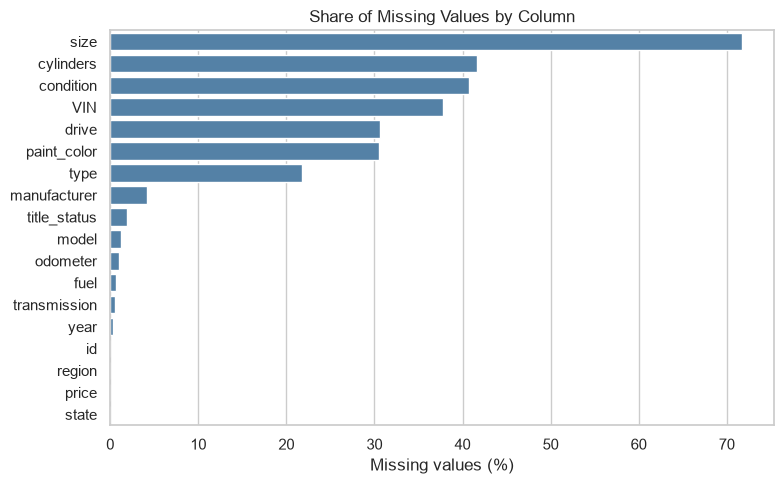

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
missing_pct = (cars_raw.isna().mean() * 100).sort_values(ascending=False)
sns.barplot(x=missing_pct.values, y=missing_pct.index, color="steelblue", ax=ax)
ax.set_title("Share of Missing Values by Column")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
plt.tight_layout()
save_figure("missing_values")

**Observations**
* `size` (72% missing), `condition`, `cylinders`, `VIN` and `drive` (30–40% missing) have heavy gaps. `size` and `VIN` are not useful predictors, so we will drop them.
* `id`, `VIN` and the free-text `region` are identifiers or very high-cardinality, so we will drop them. `state` is a compact location signal that we keep.
* `model` has about 29,600 distinct values (many are typos or variants), so we drop it and rely on `manufacturer` and `type` instead.

In [5]:
# Numeric summary reveals impossible values
cars_raw[["price", "year", "odometer"]].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(0)

,price,year,odometer
count,4.268800e+05,425675.0,422480.0
mean,7.519900e+04,2011.0,98043.0
std,1.218228e+07,9.0,213882.0
min,0.000000e+00,1900.0,0.0
1%,0.000000e+00,1967.0,2.0
5%,0.000000e+00,1998.0,6318.0
50%,1.395000e+04,2013.0,85548.0
95%,4.450000e+04,2020.0,204000.0
99%,6.699500e+04,2020.0,280000.0
max,3.736929e+09,2022.0,10000000.0


The numeric summary shows clear data-quality problems:
* **Price:** a large share of listings are $0 and the maximum is about $3.7 billion, which are placeholders or typos.
* **Odometer:** values of 0 and up to 10 million miles.
* **Year:** the oldest listing is from 1900.

We examine the raw price distribution to choose sensible cut-offs.

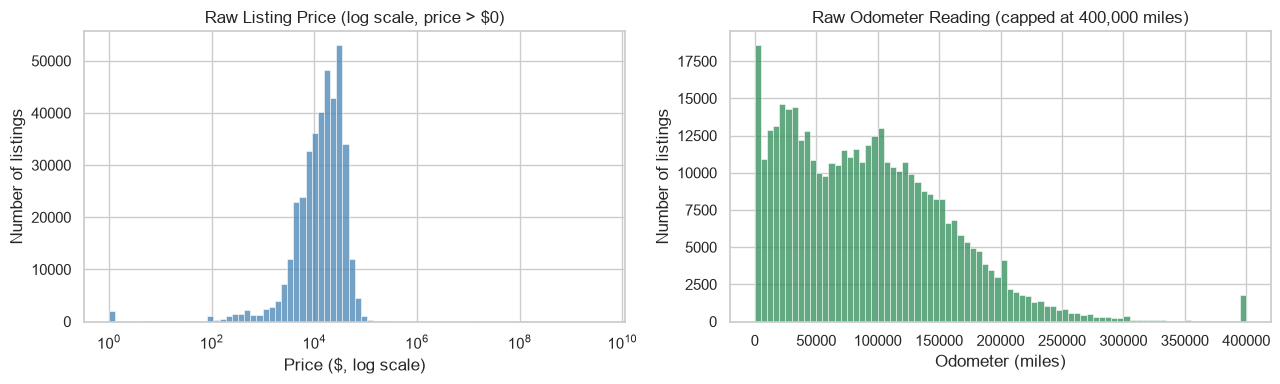

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Raw price (log-scaled x-axis, since the range spans many orders of magnitude)
sns.histplot(cars_raw.loc[cars_raw["price"] > 0, "price"], bins=80, log_scale=True, ax=axes[0], color="steelblue")
axes[0].set_title("Raw Listing Price (log scale, price > $0)")
axes[0].set_xlabel("Price ($, log scale)")
axes[0].set_ylabel("Number of listings")

sns.histplot(cars_raw["odometer"].dropna().clip(upper=400_000), bins=80, ax=axes[1], color="seagreen")
axes[1].set_title("Raw Odometer Reading (capped at 400,000 miles)")
axes[1].set_xlabel("Odometer (miles)")
axes[1].set_ylabel("Number of listings")

plt.tight_layout()
save_figure("raw_price_odometer")

## 3. Data Preparation

Cleaning decisions, each aimed at keeping realistic, comparable listings:

| Step | Rule | Rationale |
|---|---|---|
| Price | keep $1,000 – $100,000 | removes $0/placeholder listings and absurd outliers; below $1,000 listings are mostly junk or "contact for price" |
| Year | keep 1990 and later | very old cars are collectibles priced on different logic |
| Odometer | keep 1,000 – 300,000 miles | removes implausible readings |
| Duplicates | drop rows identical on the features and price | repeat postings of the same car |
| Missing categoricals | fill with `"unknown"` | keeps rows and lets the model learn whether "unspecified" itself signals price |
| Rare categories | `manufacturer`: keep as is (42 values); `cylinders`: as is | handled by one-hot encoding with a minimum frequency |
| New features | `age = 2022 − year`; `log_price`; `log_odometer` | 2022 is the latest year in the data; logs tame skew |

In [7]:
# Keep only the useful columns, then drop impossible / extreme values
feature_cols = ["year", "manufacturer", "condition", "cylinders", "fuel", "odometer",
                "title_status", "transmission", "drive", "type", "paint_color", "state"]
cars = cars_raw[["price"] + feature_cols].copy()

in_range = (
    cars["price"].between(1_000, 100_000)
    & (cars["year"] >= 1990)
    & cars["odometer"].between(1_000, 300_000)
)
cars = cars[in_range].dropna(subset=["year", "odometer"])

# Remove duplicate postings
cars = cars.drop_duplicates()

# Fill missing categorical values with an explicit label
categorical_cols = ["manufacturer", "condition", "cylinders", "fuel", "title_status",
                    "transmission", "drive", "type", "paint_color", "state"]
cars[categorical_cols] = cars[categorical_cols].fillna("unknown")

# Engineered features
cars["age"] = 2022 - cars["year"]
cars["log_odometer"] = np.log(cars["odometer"])
cars["log_price"] = np.log(cars["price"])

print(f"Rows kept: {len(cars):,} of {len(cars_raw):,} ({len(cars) / len(cars_raw):.0%})")
cars[["price", "age", "odometer"]].describe().round(0)

Rows kept: 248,980 of 426,880 (58%)


,price,age,odometer
count,248980.0,248980.0,248980.0
mean,17962.0,10.0,98982.0
std,13797.0,6.0,61980.0
min,1000.0,0.0,1000.0
25%,6999.0,5.0,45339.0
50%,14495.0,9.0,95346.0
75%,25985.0,14.0,141958.0
max,100000.0,32.0,300000.0


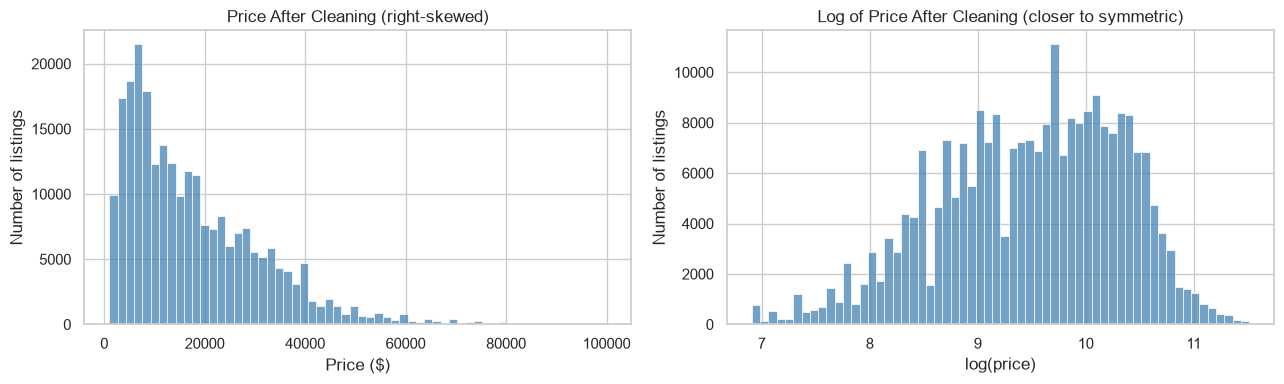

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(cars["price"], bins=60, ax=axes[0], color="steelblue")
axes[0].set_title("Price After Cleaning (right-skewed)")
axes[0].set_xlabel("Price ($)")
axes[0].set_ylabel("Number of listings")

sns.histplot(cars["log_price"], bins=60, ax=axes[1], color="steelblue")
axes[1].set_title("Log of Price After Cleaning (closer to symmetric)")
axes[1].set_xlabel("log(price)")
axes[1].set_ylabel("Number of listings")

plt.tight_layout()
save_figure("price_clean_vs_log")

Taking the log makes the target much more symmetric, which suits linear models and makes errors proportional.

### Exploring relationships with price

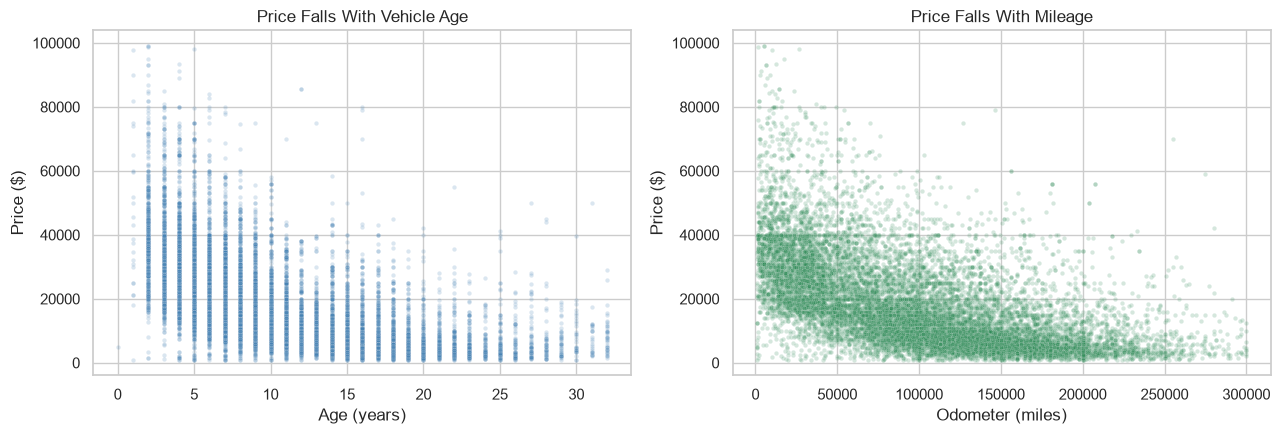

In [9]:
# Sample for readable scatter plots
sample = cars.sample(15_000, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=sample, x="age", y="price", alpha=0.2, s=10, ax=axes[0], color="steelblue")
axes[0].set_title("Price Falls With Vehicle Age")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Price ($)")

sns.scatterplot(data=sample, x="odometer", y="price", alpha=0.2, s=10, ax=axes[1], color="seagreen")
axes[1].set_title("Price Falls With Mileage")
axes[1].set_xlabel("Odometer (miles)")
axes[1].set_ylabel("Price ($)")
plt.tight_layout()
save_figure("price_vs_age_odometer")

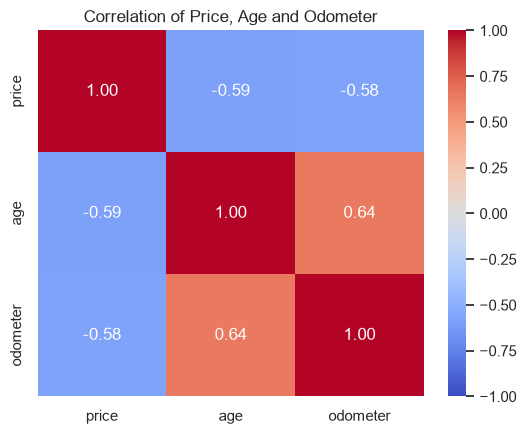

In [10]:
# Correlation among numeric variables
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cars[["price", "age", "odometer"]].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation of Price, Age and Odometer")
plt.tight_layout()
save_figure("correlation_heatmap")

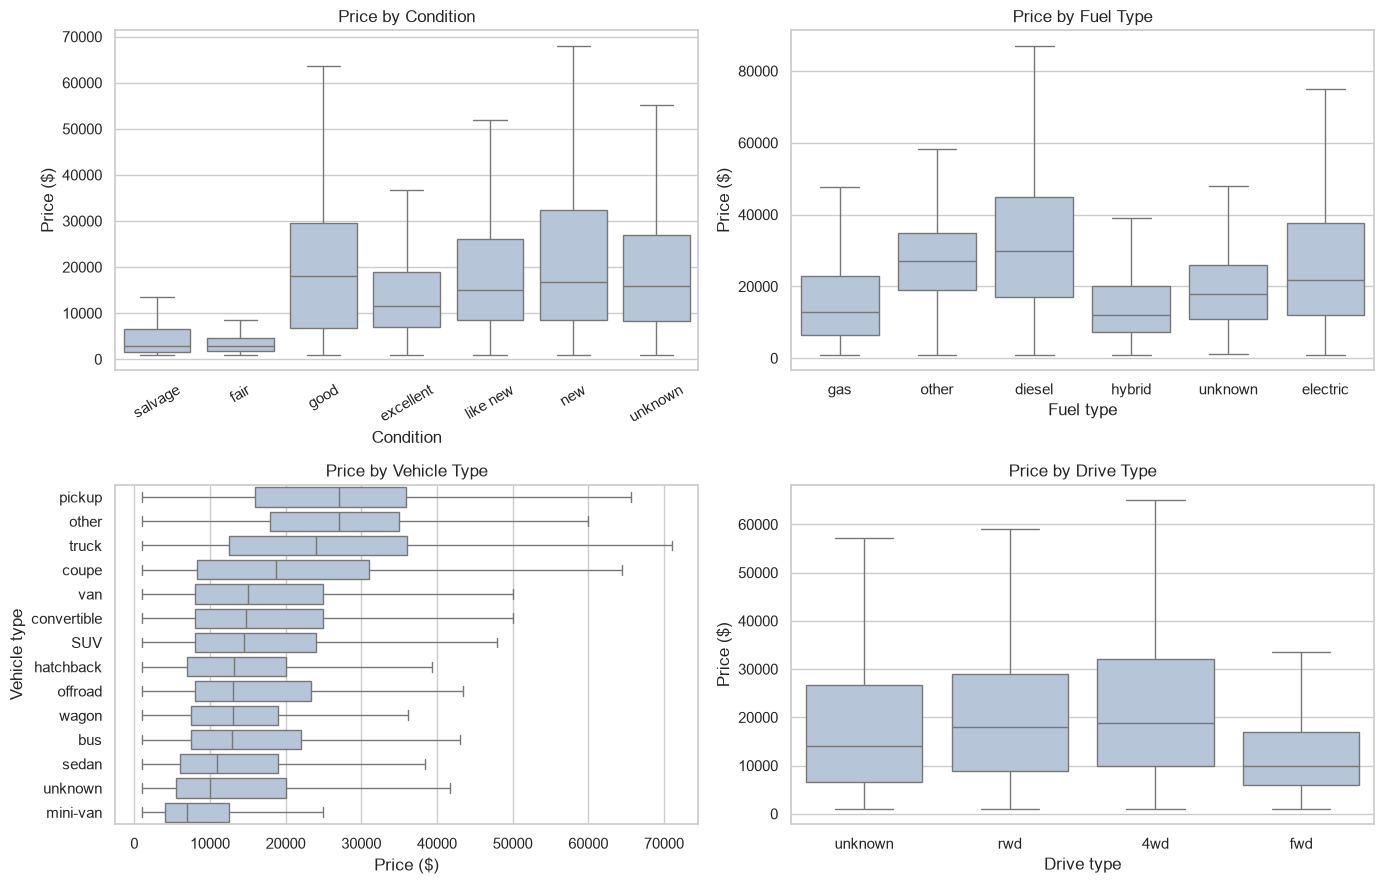

In [11]:
# Median price by key categorical variables
order_condition = ["salvage", "fair", "good", "excellent", "like new", "new", "unknown"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.boxplot(data=cars, x="condition", y="price", order=order_condition, showfliers=False, ax=axes[0, 0], color="lightsteelblue")
axes[0, 0].set_title("Price by Condition")
axes[0, 0].set_xlabel("Condition")
axes[0, 0].set_ylabel("Price ($)")
axes[0, 0].tick_params(axis="x", rotation=30)

sns.boxplot(data=cars, x="fuel", y="price", showfliers=False, ax=axes[0, 1], color="lightsteelblue")
axes[0, 1].set_title("Price by Fuel Type")
axes[0, 1].set_xlabel("Fuel type")
axes[0, 1].set_ylabel("Price ($)")

type_order = cars.groupby("type")["price"].median().sort_values(ascending=False).index
sns.boxplot(data=cars, x="price", y="type", order=type_order, showfliers=False, ax=axes[1, 0], color="lightsteelblue")
axes[1, 0].set_title("Price by Vehicle Type")
axes[1, 0].set_xlabel("Price ($)")
axes[1, 0].set_ylabel("Vehicle type")

sns.boxplot(data=cars, x="drive", y="price", showfliers=False, ax=axes[1, 1], color="lightsteelblue")
axes[1, 1].set_title("Price by Drive Type")
axes[1, 1].set_xlabel("Drive type")
axes[1, 1].set_ylabel("Price ($)")

plt.tight_layout()
save_figure("price_by_category")

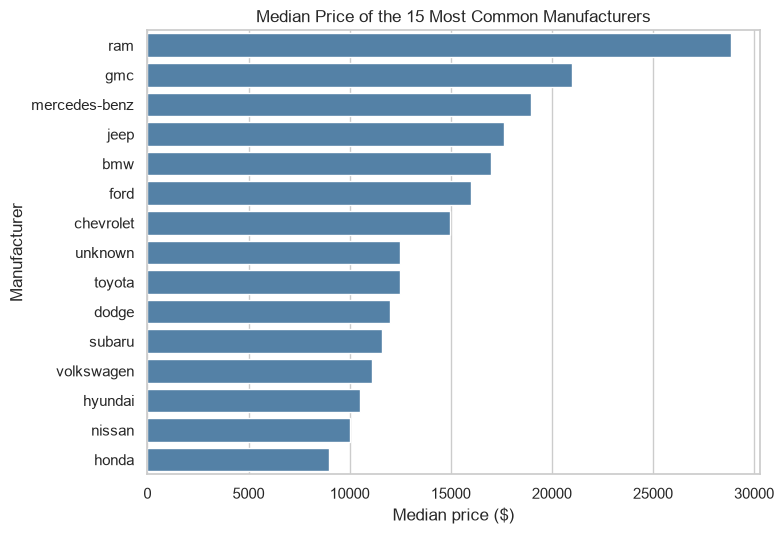

In [12]:
# Median price for the 15 most common manufacturers
top_makes = cars["manufacturer"].value_counts().head(15).index
make_median = (cars[cars["manufacturer"].isin(top_makes)]
               .groupby("manufacturer")["price"].median().sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(8, 5.5))
sns.barplot(x=make_median.values, y=make_median.index, color="steelblue", ax=ax)
ax.set_title("Median Price of the 15 Most Common Manufacturers")
ax.set_xlabel("Median price ($)")
ax.set_ylabel("Manufacturer")
plt.tight_layout()
save_figure("median_price_by_manufacturer")

### Inferential checks

Before modeling, we test whether the visible differences are statistically meaningful.

In [13]:
# 1) Is price significantly correlated with age and mileage? (Spearman handles skew and non-linearity)
for col in ["age", "odometer"]:
    rho, p_value = stats.spearmanr(cars[col], cars["price"])
    print(f"Spearman correlation of price with {col}: rho = {rho:.2f}, p = {p_value:.1e}")

# 2) Do mean log prices differ across condition levels? (one-way ANOVA)
groups = [g["log_price"].values for _, g in cars[cars["condition"] != "unknown"].groupby("condition")]
f_stat, p_value = stats.f_oneway(*groups)
print(f"ANOVA of log price across condition levels: F = {f_stat:.0f}, p = {p_value:.1e}")

# 3) Diesel vs gas (Welch t-test on log price)
diesel = cars.loc[cars["fuel"] == "diesel", "log_price"]
gas = cars.loc[cars["fuel"] == "gas", "log_price"]
t_stat, p_value = stats.ttest_ind(diesel, gas, equal_var=False)
print(f"Welch t-test diesel vs gas (log price): t = {t_stat:.1f}, p = {p_value:.1e}")

Spearman correlation of price with age: rho = -0.72, p = 0.0e+00
Spearman correlation of price with odometer: rho = -0.66, p = 0.0e+00
ANOVA of log price across condition levels: F = 3485, p = 0.0e+00
Welch t-test diesel vs gas (log price): t = 124.9, p = 0.0e+00


All three tests are highly significant (with this many rows nearly any difference is, so we focus on *effect size* in the models below). Age and mileage have a strong negative relationship with price, and condition and fuel type clearly separate price levels.

## 4. Modeling

**Setup**
* Target: `log_price`. Features: `age`, `log_odometer`, and the categorical columns.
* 80/20 train/test split. The test set is untouched until the final evaluation.
* Preprocessing happens inside a `Pipeline` so that scaling and encoding are learned only from the training folds (no leakage).
* Linear models: numeric features are standardized and categoricals are one-hot encoded (rare categories grouped).
* Hyperparameters are tuned with `GridSearchCV` (5-fold cross-validation, scored by RMSE). For speed, grid searches run on a 60,000-row subsample of the training set, and the best settings are refit on the full training set.

In [14]:
numeric_features = ["age", "log_odometer"]
X = cars[numeric_features + categorical_cols]
y = cars["log_price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

# Subsample of the training data used only for hyperparameter search
X_tune = X_train.sample(60_000, random_state=RANDOM_STATE)
y_tune = y_train.loc[X_tune.index]

linear_preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100), categorical_cols),
])

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

print(f"Train rows: {len(X_train):,}   Test rows: {len(X_test):,}")

Train rows: 199,184   Test rows: 49,796


### 4.1 Baseline: ordinary linear regression

In [15]:
linear_baseline = Pipeline([("prep", linear_preprocessor), ("model", LinearRegression())])
cv_rmse = -cross_val_score(linear_baseline, X_tune, y_tune, cv=5, scoring="neg_root_mean_squared_error")
print(f"Linear regression 5-fold CV RMSE (log price): {cv_rmse.mean():.3f} +/- {cv_rmse.std():.3f}")

Linear regression 5-fold CV RMSE (log price): 0.433 +/- 0.009


### 4.2 Regularized models: Ridge and Lasso (grid search)

Ridge shrinks correlated coefficients, and Lasso can set unhelpful ones to exactly zero (feature selection).

In [16]:
ridge_search = GridSearchCV(
    Pipeline([("prep", linear_preprocessor), ("model", Ridge())]),
    param_grid={"model__alpha": [0.1, 1, 10, 100, 1000]},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
ridge_search.fit(X_tune, y_tune)

lasso_search = GridSearchCV(
    Pipeline([("prep", linear_preprocessor), ("model", Lasso(max_iter=5000))]),
    param_grid={"model__alpha": [0.0001, 0.001, 0.01, 0.1]},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
lasso_search.fit(X_tune, y_tune)

print(f"Ridge best alpha: {ridge_search.best_params_['model__alpha']}   CV RMSE: {-ridge_search.best_score_:.3f}")
print(f"Lasso best alpha: {lasso_search.best_params_['model__alpha']}   CV RMSE: {-lasso_search.best_score_:.3f}")

Ridge best alpha: 1   CV RMSE: 0.433
Lasso best alpha: 0.0001   CV RMSE: 0.433


### 4.3 Gradient boosting (non-linear)

Price depends on interactions (for example, mileage matters differently for a truck than a compact), which linear models cannot capture. A gradient-boosted tree model handles these automatically.

In [17]:
tree_preprocessor = ColumnTransformer([
    ("num", "passthrough", numeric_features),
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical_cols),
])
# Columns 2 onward are the ordinal-encoded categoricals
categorical_mask = [False] * len(numeric_features) + [True] * len(categorical_cols)

def make_boosting(**params):
    return Pipeline([
        ("prep", tree_preprocessor),
        ("model", HistGradientBoostingRegressor(categorical_features=categorical_mask,
                                                random_state=RANDOM_STATE, **params)),
    ])

boosting_search = GridSearchCV(
    make_boosting(),
    param_grid={"model__learning_rate": [0.05, 0.1],
                "model__max_depth": [6, 10],
                "model__max_iter": [200, 400]},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
boosting_search.fit(X_tune, y_tune)
print("Boosting best parameters:", boosting_search.best_params_)
print(f"Boosting CV RMSE: {-boosting_search.best_score_:.3f}")

Boosting best parameters: {'model__learning_rate': 0.05, 'model__max_depth': 10, 'model__max_iter': 400}
Boosting CV RMSE: 0.353


## 5. Evaluation

Each tuned model is refit on the full training set and scored once on the untouched test set.

In [18]:
best_models = {
    "Linear regression": linear_baseline,
    "Ridge": Pipeline([("prep", linear_preprocessor),
                       ("model", Ridge(alpha=ridge_search.best_params_["model__alpha"]))]),
    "Lasso": Pipeline([("prep", linear_preprocessor),
                       ("model", Lasso(alpha=lasso_search.best_params_["model__alpha"], max_iter=5000))]),
    "Gradient boosting": make_boosting(**{k.replace("model__", ""): v
                                          for k, v in boosting_search.best_params_.items()}),
}

cv_scores = {
    "Linear regression": -cross_val_score(linear_baseline, X_tune, y_tune, cv=5,
                                          scoring="neg_root_mean_squared_error").mean(),
    "Ridge": -ridge_search.best_score_,
    "Lasso": -lasso_search.best_score_,
    "Gradient boosting": -boosting_search.best_score_,
}

rows = []
for name, model in best_models.items():
    model.fit(X_train, y_train)
    pred_log = model.predict(X_test)
    rows.append({
        "model": name,
        "CV RMSE (log)": cv_scores[name],
        "test RMSE (log)": rmse(y_test, pred_log),
        "test R2 (log)": r2_score(y_test, pred_log),
        "test MAE ($)": mean_absolute_error(np.exp(y_test), np.exp(pred_log)),
    })

results = pd.DataFrame(rows).set_index("model").round(3)
results

,CV RMSE (log),test RMSE (log),test R2 (log),test MAE ($)
model,,,,
Linear regression,0.433,0.432,0.742,4911.476
Ridge,0.433,0.432,0.742,4911.353
Lasso,0.433,0.432,0.742,4908.674
Gradient boosting,0.353,0.348,0.833,3403.880


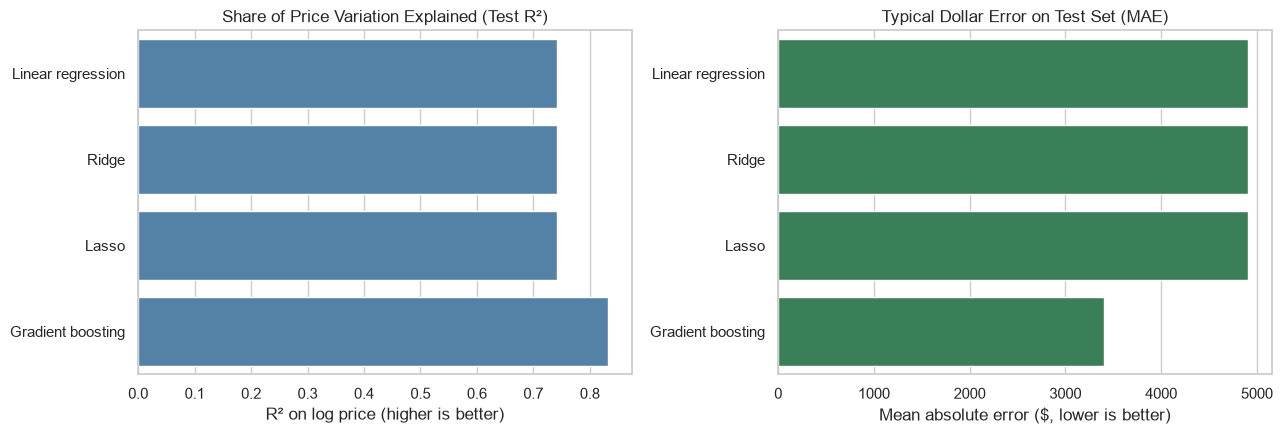

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(x=results["test R2 (log)"], y=results.index, color="steelblue", ax=axes[0])
axes[0].set_title("Share of Price Variation Explained (Test R²)")
axes[0].set_xlabel("R² on log price (higher is better)")
axes[0].set_ylabel("")

sns.barplot(x=results["test MAE ($)"], y=results.index, color="seagreen", ax=axes[1])
axes[1].set_title("Typical Dollar Error on Test Set (MAE)")
axes[1].set_xlabel("Mean absolute error ($, lower is better)")
axes[1].set_ylabel("")

plt.tight_layout()
save_figure("model_comparison")

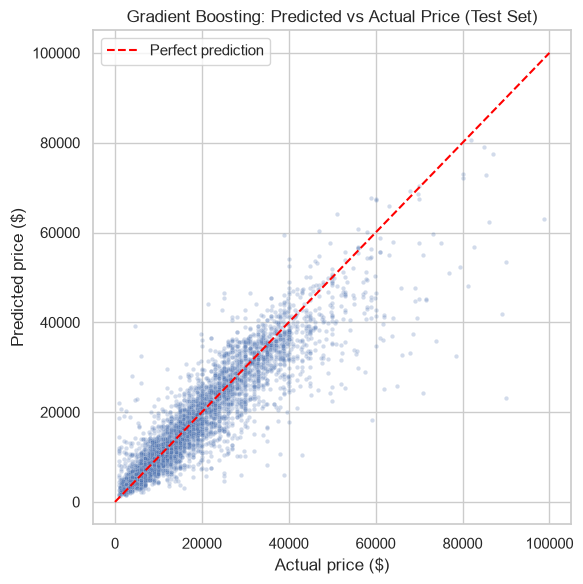

In [20]:
# Predicted vs actual for the best model
final_model = best_models["Gradient boosting"]
test_pred = np.exp(final_model.predict(X_test))
test_actual = np.exp(y_test)
plot_idx = np.random.RandomState(RANDOM_STATE).choice(len(test_actual), 5_000, replace=False)

fig, ax = plt.subplots(figsize=(6, 6))
sns.scatterplot(x=test_actual.values[plot_idx], y=test_pred[plot_idx], alpha=0.25, s=10, ax=ax)
ax.plot([0, 100_000], [0, 100_000], color="red", linestyle="--", label="Perfect prediction")
ax.set_title("Gradient Boosting: Predicted vs Actual Price (Test Set)")
ax.set_xlabel("Actual price ($)")
ax.set_ylabel("Predicted price ($)")
ax.legend()
plt.tight_layout()
save_figure("predicted_vs_actual")

### Interpreting the drivers of price

All figures in this notebook are also saved as PNG files in the `images/` folder.

**Linear model coefficients.** Because the target is `log(price)`, a coefficient *b* means price changes by about `exp(b) − 1` (a percentage) for a one-unit change, holding other variables fixed. Numeric features are standardized, so their coefficients are per one standard deviation. Every category level gets its own column (no baseline is dropped), and Ridge shrinks them toward each other, so each categorical coefficient is best read as a premium or discount relative to the average level of that variable, not as an exact dollar effect. Catch-all levels ("unknown", "other", grouped rare categories) are hidden from the chart because they have no clear meaning.

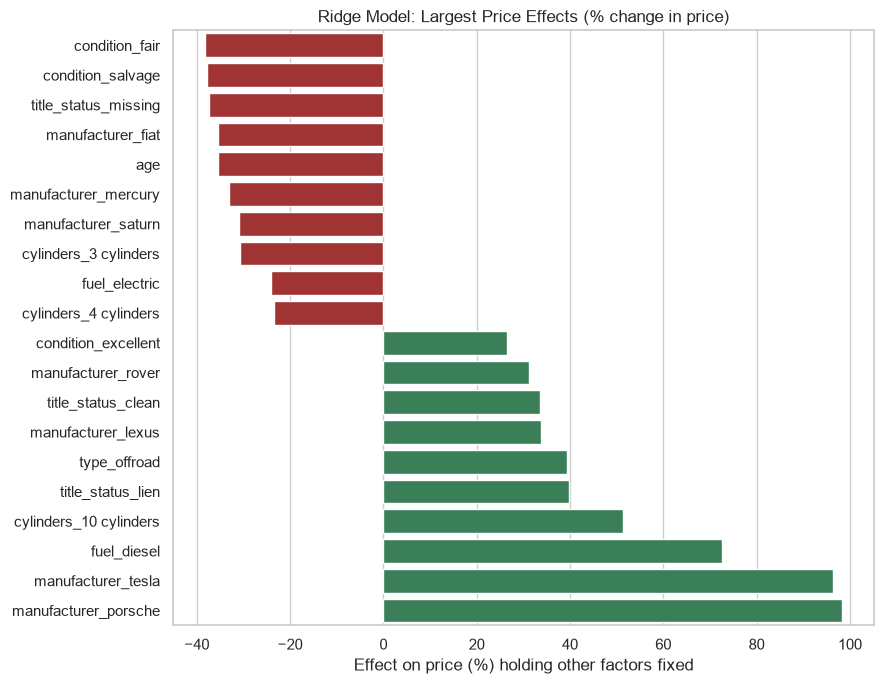

In [21]:
ridge_final = best_models["Ridge"]
feature_names = ridge_final.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(ridge_final.named_steps["model"].coef_, index=feature_names)
coefs.index = coefs.index.str.replace("num__", "", regex=False).str.replace("cat__", "", regex=False)
price_effect_pct = (np.exp(coefs) - 1) * 100

# Show the largest effects among interpretable features (drop state, colour, and catch-all
# levels such as "unknown" or grouped rare categories, which have no clear meaning)
hidden = ("state_", "paint_color_")
interpretable = price_effect_pct[
    ~price_effect_pct.index.str.startswith(hidden)
    & ~price_effect_pct.index.str.contains("infrequent|unknown|other")
]
top_effects = pd.concat([interpretable.nlargest(10), interpretable.nsmallest(10)]).sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
colors = ["firebrick" if v < 0 else "seagreen" for v in top_effects.values]
sns.barplot(x=top_effects.values, y=top_effects.index, palette=colors, ax=ax)
ax.set_title("Ridge Model: Largest Price Effects (% change in price)")
ax.set_xlabel("Effect on price (%) holding other factors fixed")
ax.set_ylabel("")
plt.tight_layout()
save_figure("ridge_price_effects")

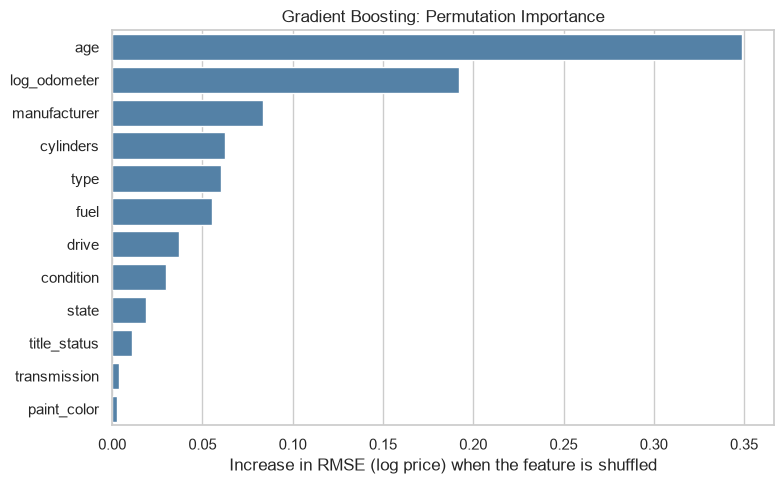

In [22]:
# Permutation importance for the boosting model: how much does shuffling a feature hurt accuracy?
test_sample = X_test.sample(10_000, random_state=RANDOM_STATE)
perm = permutation_importance(final_model, test_sample, y_test.loc[test_sample.index],
                              n_repeats=5, random_state=RANDOM_STATE, scoring="neg_root_mean_squared_error")
importance = pd.Series(perm.importances_mean, index=test_sample.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=importance.values, y=importance.index, color="steelblue", ax=ax)
ax.set_title("Gradient Boosting: Permutation Importance")
ax.set_xlabel("Increase in RMSE (log price) when the feature is shuffled")
ax.set_ylabel("")
plt.tight_layout()
save_figure("permutation_importance")

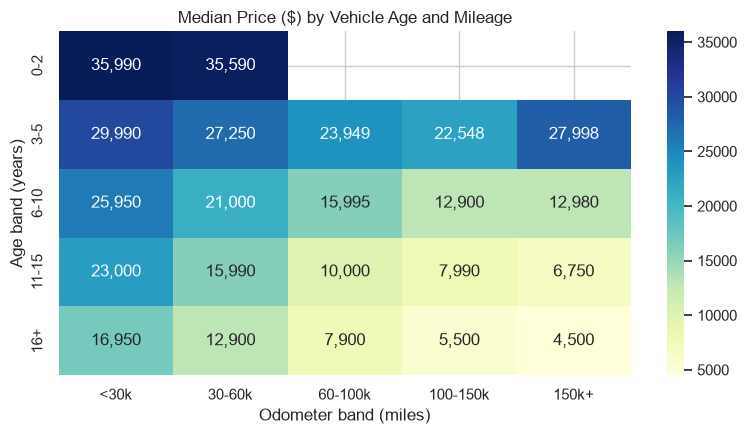

In [23]:
# Dollar impact of the most important dimensions, via median price by age band and mileage band
cars["age_band"] = pd.cut(cars["age"], [-1, 2, 5, 10, 15, 40], labels=["0-2", "3-5", "6-10", "11-15", "16+"])
cars["mileage_band"] = pd.cut(cars["odometer"], [0, 30_000, 60_000, 100_000, 150_000, 300_000],
                              labels=["<30k", "30-60k", "60-100k", "100-150k", "150k+"])
pivot = cars.pivot_table(index="age_band", columns="mileage_band", values="price", aggfunc="median", observed=True)
# Hide cells built from fewer than 100 listings, since their medians are unreliable
cell_counts = cars.pivot_table(index="age_band", columns="mileage_band", values="price", aggfunc="size", observed=True)
pivot = pivot.where(cell_counts >= 100)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="YlGnBu", ax=ax)
ax.set_title("Median Price ($) by Vehicle Age and Mileage")
ax.set_xlabel("Odometer band (miles)")
ax.set_ylabel("Age band (years)")
plt.tight_layout()
save_figure("age_mileage_heatmap")

## 6. Findings and Recommendations (Deployment)

### How good is the model?
* The best model (**gradient boosting**) explains about **83% of the variation in used car prices** (test R² = 0.83 on log price) and is off by a typical **$3,400** on cars that average about $18,000. Simple linear models explain about 74% and miss by about $4,900.
* Ridge, Lasso and plain linear regression performed identically, so the extra accuracy comes from capturing **interactions** (for example, mileage matters differently for a truck than for a compact car), not from tuning.
* These are **asking prices** from Craigslist, not final sale prices, and the results show association, not cause.

### What drives price (most to least important)
1. **Age.** The single biggest driver. Each additional 6 years of age (one standard deviation) is associated with a price roughly **35% lower**, holding everything else fixed.
2. **Mileage.** The second biggest driver. Among 6–10 year-old cars, the median price drops from about $26,000 under 30k miles to about $13,000 over 100k miles.
3. **Manufacturer, engine size (cylinders), body type and fuel.** Premium brands (Porsche, Tesla, Lexus) carry large premiums (Porsche and Tesla roughly double the price of a comparable average-brand car, and Lexus about a third higher). **Diesel** carries a premium of roughly 70% over gas, and off-road and large-engine vehicles are priced higher.
4. **Drive type, condition and title status.** A **salvage or fair** condition rating is associated with about **35% lower** prices, and a missing title record with about 35% lower prices.
5. **Little to no effect:** paint color and transmission add almost nothing once the factors above are known.

### Recommendations for the dealership
* **Buy younger, lower-mileage cars where margins allow.** Age and mileage explain the most price. Cars under 5 years old and under 60,000 miles hold value best.
* **Look for the "sweet spot" of 6–10 year-old cars under 60,000 miles.** They are priced about 20–40% below near-new cars but well above high-mileage cars of the same age.
* **Stock premium brands and diesel trucks/SUVs** if the goal is higher ticket prices, but check turnover, since pricier cars may sit longer.
* **Avoid or discount salvage, rebuilt and unclear-title vehicles.** Buyers pay much less for them.
* **Always record condition, cylinders and drive type in your listings.** Roughly 30–40% of listings leave these blank, and complete listings are easier to price against the market.
* **Don't spend on paint-color or transmission premiums** when choosing inventory.

### Next steps
* Add the vehicle `model` field, cleaned into trims, and measure the extra accuracy.
* Use actual **sale prices and days-on-lot** (not asking prices) to turn these price drivers into profit and turnover drivers.
* Build a simple pricing tool from the model so staff can benchmark an incoming trade-in.
* Refresh the model regularly, because used car markets shift quickly.